In [1]:
import sys
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.version)
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Python: 3.12.3 (main, Jun 19 2026, 12:46:00) [GCC 13.3.0]
OpenCV: 5.0.0
NumPy: 2.3.5
Pandas: 2.3.3


In [2]:
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent.parent
SPORTSMOT_FOOTBALL = (
    PROJECT_ROOT
    / "datasets"
    / "football"
    / "benchmarks"
    / "sportsmot"
    / "extracted"
)
print("Project root:")
print(PROJECT_ROOT)
print("\nSportsMOT Football:")
print(SPORTSMOT_FOOTBALL)
print("\nPath exists:", SPORTSMOT_FOOTBALL.exists())

Project root:
/mnt/d/My Projects/AthletiQ/AthletiQ

SportsMOT Football:
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted

Path exists: True


In [3]:
train_dir = SPORTSMOT_FOOTBALL / "train"
val_dir = SPORTSMOT_FOOTBALL / "val"

train_sequences = sorted([p for p in train_dir.iterdir() if p.is_dir()])
val_sequences = sorted([p for p in val_dir.iterdir() if p.is_dir()])

print("Football training sequences:", len(train_sequences))
print("Football validation sequences:", len(val_sequences))

print("\nTraining sequences:")
for seq in train_sequences:
    print(" ", seq.name)

print("\nValidation sequences:")
for seq in val_sequences:
    print(" ", seq.name)

Football training sequences: 15
Football validation sequences: 15

Training sequences:
  v_1yHWGw8DH4A_c029
  v_1yHWGw8DH4A_c047
  v_1yHWGw8DH4A_c077
  v_1yHWGw8DH4A_c601
  v_1yHWGw8DH4A_c609
  v_1yHWGw8DH4A_c610
  v_HdiyOtliFiw_c003
  v_HdiyOtliFiw_c004
  v_HdiyOtliFiw_c008
  v_HdiyOtliFiw_c010
  v_HdiyOtliFiw_c602
  v_gQNyhv8y0QY_c003
  v_gQNyhv8y0QY_c012
  v_gQNyhv8y0QY_c013
  v_iIxMOsCGH58_c013

Validation sequences:
  v_2QhNRucNC7E_c017
  v_G-vNjfx1GGc_c004
  v_G-vNjfx1GGc_c008
  v_G-vNjfx1GGc_c600
  v_G-vNjfx1GGc_c601
  v_ITo3sCnpw_k_c007
  v_ITo3sCnpw_k_c010
  v_ITo3sCnpw_k_c011
  v_ITo3sCnpw_k_c012
  v_dw7LOz17Omg_c053
  v_dw7LOz17Omg_c067
  v_i2_L4qquVg0_c006
  v_i2_L4qquVg0_c007
  v_i2_L4qquVg0_c009
  v_i2_L4qquVg0_c010


In [4]:
def sequence_statistics(sequence_path):
    img_dir = sequence_path / "img1"
    gt_file = sequence_path / "gt" / "gt.txt"

    image_files = sorted(img_dir.glob("*.jpg"))
    num_frames = len(image_files)

    gt = pd.read_csv(
        gt_file,
        header=None,
        names=[
            "frame",
            "track_id",
            "x",
            "y",
            "width",
            "height",
            "mark",
            "class",
            "visibility"
        ]
    )
    
    width, height = None, None
    if image_files:
        image = cv2.imread(str(image_files[0]))
        if image is not None:
            height, width = image.shape[:2]

    return {
        "sequence": sequence_path.name,
        "frames": num_frames,
        "gt_annotations": len(gt),
        "unique_tracks": gt["track_id"].nunique(),
        "width": width,
        "height": height
    }

all_sequences = train_sequences + val_sequences
stats = pd.DataFrame(
    [sequence_statistics(seq) for seq in all_sequences]
)

stats

,sequence,frames,gt_annotations,unique_tracks,width,height
0,v_1yHWGw8DH4A_c029,725,9989,22,1280,720
1,v_1yHWGw8DH4A_c047,537,6135,21,1280,720
2,v_1yHWGw8DH4A_c077,1197,16229,22,1280,720
3,v_1yHWGw8DH4A_c601,552,6834,18,1280,720
4,v_1yHWGw8DH4A_c609,500,7364,21,1280,720
5,v_1yHWGw8DH4A_c610,535,7254,18,1280,720
6,v_HdiyOtliFiw_c003,775,11518,21,1280,720
7,v_HdiyOtliFiw_c004,1025,13273,20,1280,720
8,v_HdiyOtliFiw_c008,549,7800,21,1280,720
9,v_HdiyOtliFiw_c010,892,14356,21,1280,720


In [5]:
total_frames = stats["frames"].sum()
total_annotations = stats["gt_annotations"].sum()

print("Overall SportsMOT Football Statistics")
print("=" * 45)

print(f"Total sequences       : {len(stats)}")
print(f"Training sequences    : {len(train_sequences)}")
print(f"Validation sequences  : {len(val_sequences)}")
print(f"Total frames          : {total_frames:,}")
print(f"Total GT annotations  : {total_annotations:,}")
print(f"Average frames/seq    : {stats['frames'].mean():.2f}")
print(f"Average GT/seq        : {stats['gt_annotations'].mean():.2f}")
print(f"Average tracks/seq    : {stats['unique_tracks'].mean():.2f}")

print("\nResolution")
print("-" * 45)
print(f"Width                 : {stats['width'].unique()}")
print(f"Height                : {stats['height'].unique()}")

Overall SportsMOT Football Statistics
Total sequences       : 30
Training sequences    : 15
Validation sequences  : 15
Total frames          : 20,171
Total GT annotations  : 262,343
Average frames/seq    : 672.37
Average GT/seq        : 8744.77
Average tracks/seq    : 20.67

Resolution
---------------------------------------------
Width                 : [1280]
Height                : [720]


In [6]:
objects_per_frame = []
for seq in all_sequences:
    gt_file = seq / "gt" / "gt.txt"

    gt = pd.read_csv(
        gt_file,
        header=None,
        names=[
            "frame",
            "track_id",
            "x",
            "y",
            "width",
            "height",
            "mark",
            "class",
            "visibility"
        ]
    )
    frame_counts = gt.groupby("frame").size()

    for frame, count in frame_counts.items():
        objects_per_frame.append({
            "sequence": seq.name,
            "frame": frame,
            "objects": count
        })

objects_per_frame = pd.DataFrame(objects_per_frame)

print("Total annotated frames:", len(objects_per_frame))
print("Minimum objects/frame :", objects_per_frame["objects"].min())
print("Maximum objects/frame :", objects_per_frame["objects"].max())
print("Average objects/frame :", f"{objects_per_frame['objects'].mean():.2f}")
print("Median objects/frame  :", f"{objects_per_frame['objects'].median():.2f}")

Total annotated frames: 20171
Minimum objects/frame : 1
Maximum objects/frame : 21
Average objects/frame : 13.01
Median objects/frame  : 13.00


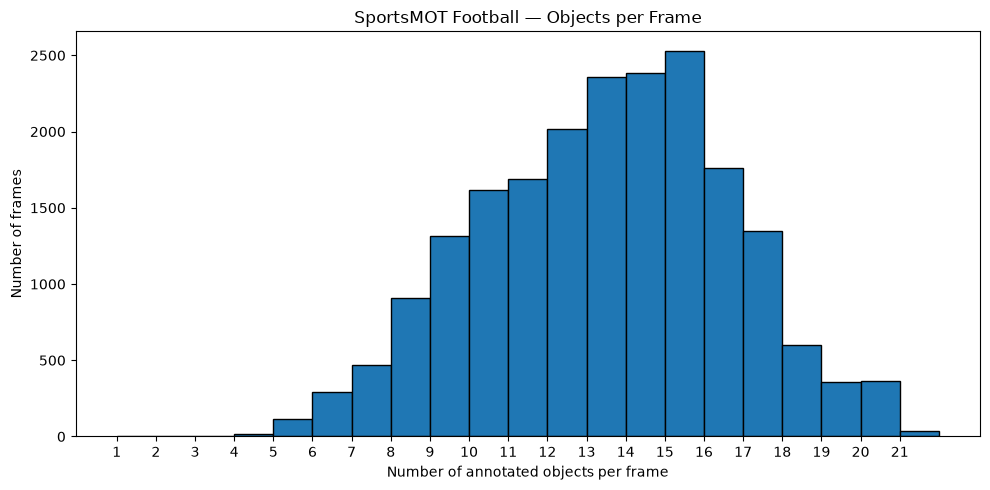

In [7]:
plt.figure(figsize=(10, 5))
plt.hist(
    objects_per_frame["objects"],
    bins=range(
        objects_per_frame["objects"].min(),
        objects_per_frame["objects"].max() + 2
    ),
    edgecolor="black"
)
plt.xlabel("Number of annotated objects per frame")
plt.ylabel("Number of frames")
plt.title("SportsMOT Football — Objects per Frame")
plt.xticks(
    range(
        objects_per_frame["objects"].min(),
        objects_per_frame["objects"].max() + 1
    )
)

plt.tight_layout()
plt.show()

In [8]:
bbox_stats = []
for seq in all_sequences:
    gt_file = seq / "gt" / "gt.txt"

    gt = pd.read_csv(
        gt_file,
        header=None,
        names=[
            "frame",
            "track_id",
            "x",
            "y",
            "width",
            "height",
            "mark",
            "class",
            "visibility"
        ]
    )
    gt["area"] = gt["width"] * gt["height"]
    bbox_stats.append(gt[["width", "height", "area"]])

bbox_stats = pd.concat(bbox_stats, ignore_index=True)

print("Bounding-box statistics")
print("=" * 45)

print(f"Total bounding boxes : {len(bbox_stats):,}")

print("\nWidth")
print(f"Minimum              : {bbox_stats['width'].min():.2f}")
print(f"Maximum              : {bbox_stats['width'].max():.2f}")
print(f"Mean                 : {bbox_stats['width'].mean():.2f}")
print(f"Median               : {bbox_stats['width'].median():.2f}")

print("\nHeight")
print(f"Minimum              : {bbox_stats['height'].min():.2f}")
print(f"Maximum              : {bbox_stats['height'].max():.2f}")
print(f"Mean                 : {bbox_stats['height'].mean():.2f}")
print(f"Median               : {bbox_stats['height'].median():.2f}")

print("\nArea")
print(f"Minimum              : {bbox_stats['area'].min():.2f}")
print(f"Maximum              : {bbox_stats['area'].max():.2f}")
print(f"Mean                 : {bbox_stats['area'].mean():.2f}")
print(f"Median               : {bbox_stats['area'].median():.2f}")

Bounding-box statistics
Total bounding boxes : 262,343

Width
Minimum              : 5.00
Maximum              : 128.00
Mean                 : 36.96
Median               : 35.00

Height
Minimum              : 5.00
Maximum              : 174.00
Mean                 : 77.00
Median               : 76.00

Area
Minimum              : 175.00
Maximum              : 15776.00
Mean                 : 2951.72
Median               : 2688.00


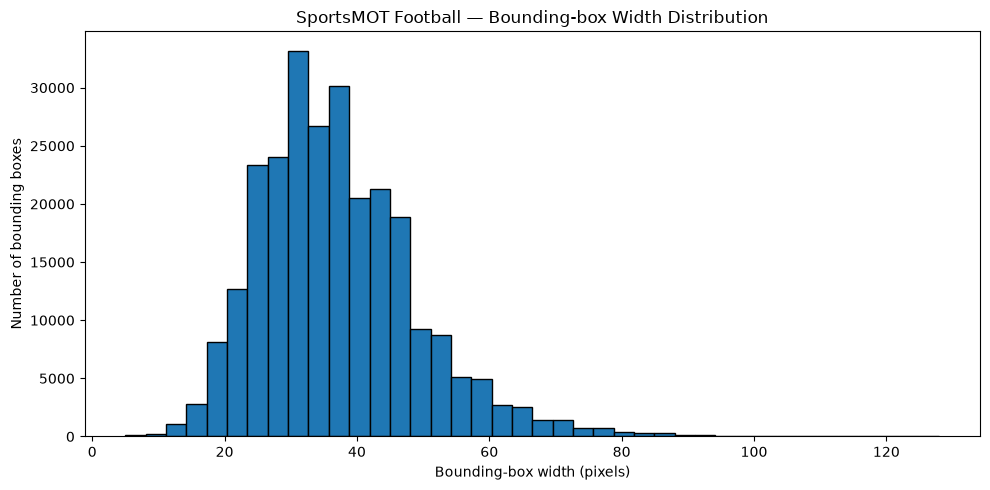

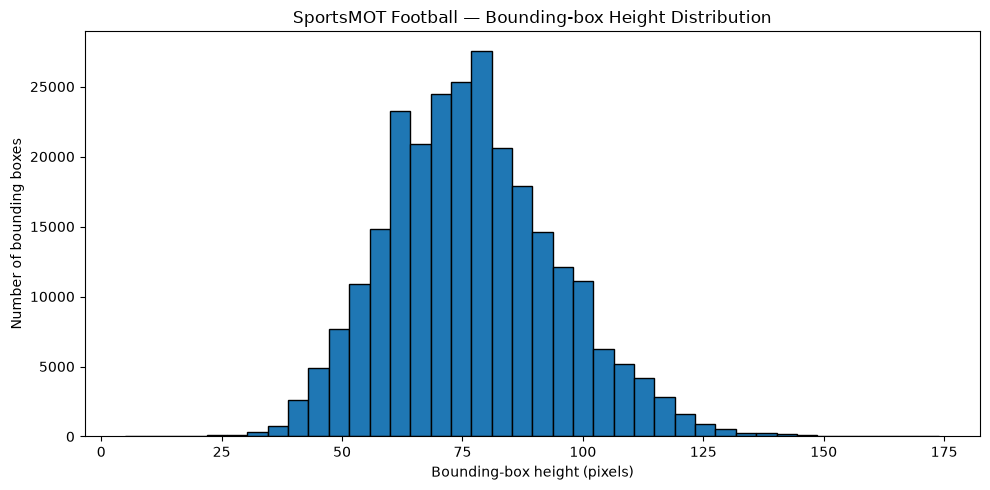

In [9]:
plt.figure(figsize=(10, 5))
plt.hist(
    bbox_stats["width"],
    bins=40,
    edgecolor="black"
)
plt.xlabel("Bounding-box width (pixels)")
plt.ylabel("Number of bounding boxes")
plt.title("SportsMOT Football — Bounding-box Width Distribution")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.hist(
    bbox_stats["height"],
    bins=40,
    edgecolor="black"
)
plt.xlabel("Bounding-box height (pixels)")
plt.ylabel("Number of bounding boxes")
plt.title("SportsMOT Football — Bounding-box Height Distribution")
plt.tight_layout()
plt.show()

In [10]:
# Check whether GT bounding boxes stay inside image boundaries

invalid_boxes = []

for seq in all_sequences:
    gt_file = seq / "gt" / "gt.txt"

    gt = pd.read_csv(
        gt_file,
        header=None,
        names=[
            "frame",
            "track_id",
            "x",
            "y",
            "width",
            "height",
            "mark",
            "class",
            "visibility"
        ]
    )

    invalid = gt[
        (gt["x"] < 0) |
        (gt["y"] < 0) |
        (gt["x"] + gt["width"] > 1280) |
        (gt["y"] + gt["height"] > 720) |
        (gt["width"] <= 0) |
        (gt["height"] <= 0)
    ].copy()

    if len(invalid) > 0:
        invalid["sequence"] = seq.name
        invalid_boxes.append(invalid)

if invalid_boxes:
    invalid_boxes = pd.concat(invalid_boxes, ignore_index=True)

    print("Invalid bounding boxes found:", len(invalid_boxes))
    print(invalid_boxes.head(20))
else:
    print("No invalid bounding boxes found.")

No invalid bounding boxes found.


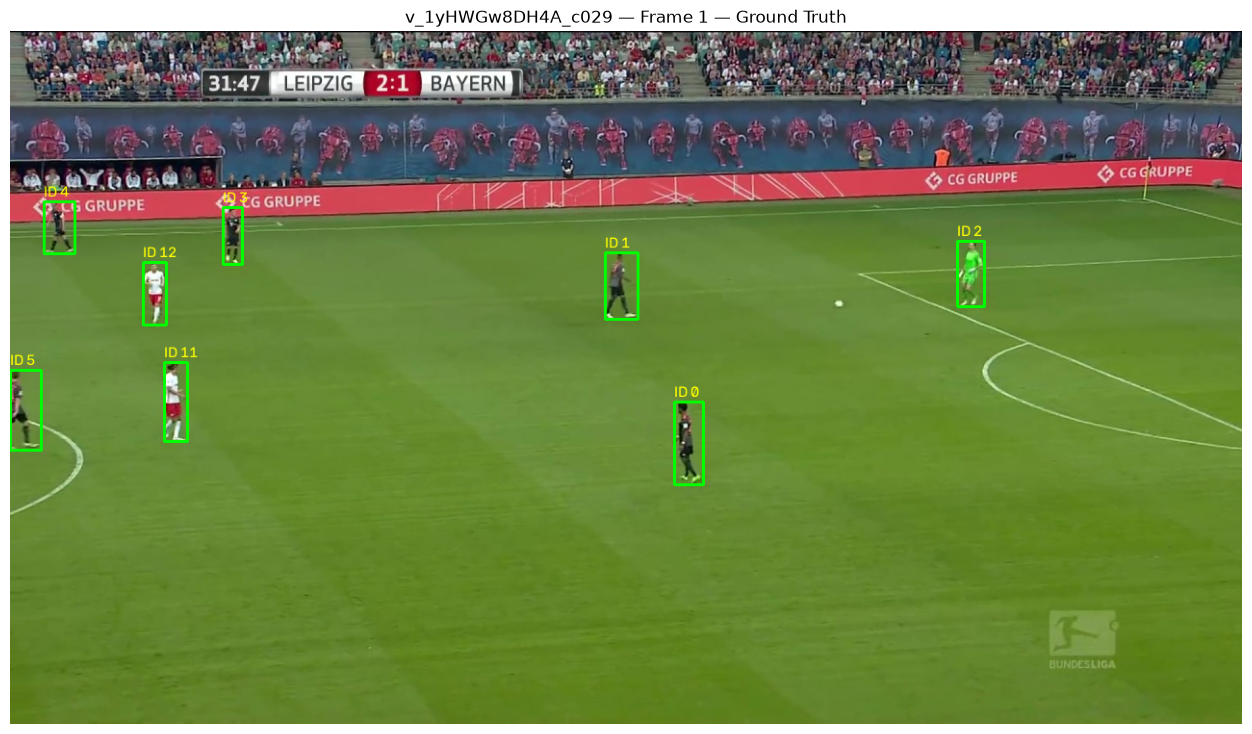

Image: 000001.jpg
Ground-truth objects in frame: 8


In [11]:
# Visualize Ground Truth bounding boxes on a frame

sequence = train_sequences[0]

image_path = sequence / "img1" / "000001.jpg"
gt_file = sequence / "gt" / "gt.txt"

# Load image
image = cv2.imread(str(image_path))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Load annotations
gt = pd.read_csv(
    gt_file,
    header=None,
    names=[
        "frame",
        "track_id",
        "x",
        "y",
        "width",
        "height",
        "mark",
        "class",
        "visibility"
    ]
)

# Select annotations for frame 1
frame_gt = gt[gt["frame"] == 1]

# Draw bounding boxes
for _, row in frame_gt.iterrows():

    x = int(row["x"])
    y = int(row["y"])
    w = int(row["width"])
    h = int(row["height"])

    cv2.rectangle(
        image,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

    cv2.putText(
        image,
        f"ID {int(row['track_id'])}",
        (x, max(y - 5, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 255, 0),
        1,
        cv2.LINE_AA
    )

plt.figure(figsize=(16, 9))
plt.imshow(image)
plt.title(f"{sequence.name} — Frame 1 — Ground Truth")
plt.axis("off")
plt.show()

print("Image:", image_path.name)
print("Ground-truth objects in frame:", len(frame_gt))

In [12]:
# Check consistency between image frames and GT annotation frames

consistency_results = []

for seq in all_sequences:

    img_dir = seq / "img1"
    gt_file = seq / "gt" / "gt.txt"

    # Get frame numbers from image filenames
    image_frames = {
        int(path.stem)
        for path in img_dir.glob("*.jpg")
        if path.stem.isdigit()
    }

    # Get frame numbers from GT
    gt = pd.read_csv(
        gt_file,
        header=None,
        names=[
            "frame",
            "track_id",
            "x",
            "y",
            "width",
            "height",
            "mark",
            "class",
            "visibility"
        ]
    )

    gt_frames = set(gt["frame"].astype(int).unique())

    # Compare
    missing_gt = image_frames - gt_frames
    missing_images = gt_frames - image_frames

    consistency_results.append({
        "sequence": seq.name,
        "image_frames": len(image_frames),
        "gt_frames": len(gt_frames),
        "images_without_gt": len(missing_gt),
        "gt_without_image": len(missing_images)
    })

consistency = pd.DataFrame(consistency_results)

print("Frame ↔ GT consistency check")
print("=" * 60)

print("Sequences with images missing GT:",
      (consistency["images_without_gt"] > 0).sum())

print("Sequences with GT missing images:",
      (consistency["gt_without_image"] > 0).sum())

print("\nDetails:")
display(consistency)

Frame ↔ GT consistency check
Sequences with images missing GT: 0
Sequences with GT missing images: 0

Details:


,sequence,image_frames,gt_frames,images_without_gt,gt_without_image
0,v_1yHWGw8DH4A_c029,725,725,0,0
1,v_1yHWGw8DH4A_c047,537,537,0,0
2,v_1yHWGw8DH4A_c077,1197,1197,0,0
3,v_1yHWGw8DH4A_c601,552,552,0,0
4,v_1yHWGw8DH4A_c609,500,500,0,0
5,v_1yHWGw8DH4A_c610,535,535,0,0
6,v_HdiyOtliFiw_c003,775,775,0,0
7,v_HdiyOtliFiw_c004,1025,1025,0,0
8,v_HdiyOtliFiw_c008,549,549,0,0
9,v_HdiyOtliFiw_c010,892,892,0,0


In [13]:
# Analyze track persistence across the Football dataset

track_stats = []

for seq in all_sequences:

    gt_file = seq / "gt" / "gt.txt"

    gt = pd.read_csv(
        gt_file,
        header=None,
        names=[
            "frame",
            "track_id",
            "x",
            "y",
            "width",
            "height",
            "mark",
            "class",
            "visibility"
        ]
    )

    # Statistics for every track in this sequence
    grouped = gt.groupby("track_id")

    for track_id, track in grouped:

        track_stats.append({
            "sequence": seq.name,
            "track_id": int(track_id),
            "frames_visible": len(track),
            "first_frame": int(track["frame"].min()),
            "last_frame": int(track["frame"].max()),
            "avg_width": track["width"].mean(),
            "avg_height": track["height"].mean()
        })

track_stats = pd.DataFrame(track_stats)

print("Track persistence statistics")
print("=" * 50)

print(f"Total unique tracks : {len(track_stats):,}")

print("\nFrames visible per track")
print(f"Minimum             : {track_stats['frames_visible'].min()}")
print(f"Maximum             : {track_stats['frames_visible'].max()}")
print(f"Mean                : {track_stats['frames_visible'].mean():.2f}")
print(f"Median              : {track_stats['frames_visible'].median():.2f}")

print("\nLongest 10 tracks:")
display(
    track_stats
    .sort_values("frames_visible", ascending=False)
    .head(10)
)

Track persistence statistics
Total unique tracks : 620

Frames visible per track
Minimum             : 2
Maximum             : 1196
Mean                : 423.13
Median              : 405.50

Longest 10 tracks:


,sequence,track_id,frames_visible,first_frame,last_frame,avg_width,avg_height
45,v_1yHWGw8DH4A_c077,2,1196,1,1197,43.545151,85.658027
49,v_1yHWGw8DH4A_c077,6,1101,1,1171,36.195277,81.728429
259,v_gQNyhv8y0QY_c012,13,1081,1,1325,45.063830,103.931545
252,v_gQNyhv8y0QY_c012,6,1031,1,1046,38.011639,95.359845
248,v_gQNyhv8y0QY_c012,2,1031,1,1050,37.037827,71.856450
44,v_1yHWGw8DH4A_c077,1,1025,1,1197,41.795122,83.148293
253,v_gQNyhv8y0QY_c012,7,1014,1,1325,39.005917,86.562130
257,v_gQNyhv8y0QY_c012,11,1005,1,1052,32.606965,76.648756
254,v_gQNyhv8y0QY_c012,8,996,1,1325,37.393574,87.201807
60,v_1yHWGw8DH4A_c077,17,993,1,1197,39.901309,81.052367


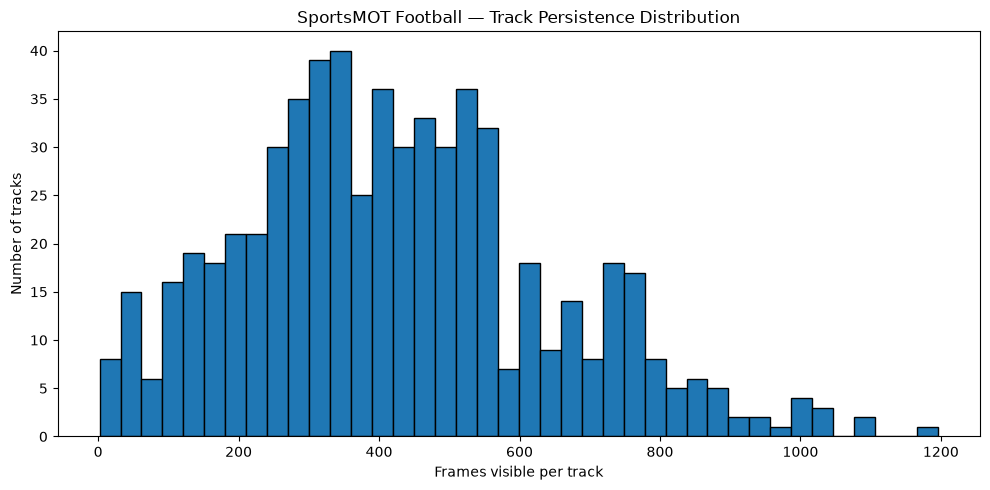

In [14]:
# Track persistence distribution

plt.figure(figsize=(10, 5))

plt.hist(
    track_stats["frames_visible"],
    bins=40,
    edgecolor="black"
)

plt.xlabel("Frames visible per track")
plt.ylabel("Number of tracks")
plt.title("SportsMOT Football — Track Persistence Distribution")

plt.tight_layout()
plt.show()

In [15]:
# Inspect annotation metadata columns

metadata_summary = []

for seq in all_sequences:

    gt_file = seq / "gt" / "gt.txt"

    gt = pd.read_csv(
        gt_file,
        header=None,
        names=[
            "frame",
            "track_id",
            "x",
            "y",
            "width",
            "height",
            "mark",
            "class",
            "visibility"
        ]
    )

    metadata_summary.append({
        "sequence": seq.name,
        "unique_mark": sorted(gt["mark"].unique().tolist()),
        "unique_class": sorted(gt["class"].unique().tolist()),
        "min_visibility": gt["visibility"].min(),
        "max_visibility": gt["visibility"].max()
    })

metadata_summary = pd.DataFrame(metadata_summary)

display(metadata_summary)

,sequence,unique_mark,unique_class,min_visibility,max_visibility
0,v_1yHWGw8DH4A_c029,[1],[1],1,1
1,v_1yHWGw8DH4A_c047,[1],[1],1,1
2,v_1yHWGw8DH4A_c077,[1],[1],1,1
3,v_1yHWGw8DH4A_c601,[1],[1],1,1
4,v_1yHWGw8DH4A_c609,[1],[1],1,1
5,v_1yHWGw8DH4A_c610,[1],[1],1,1
6,v_HdiyOtliFiw_c003,[1],[1],1,1
7,v_HdiyOtliFiw_c004,[1],[1],1,1
8,v_HdiyOtliFiw_c008,[1],[1],1,1
9,v_HdiyOtliFiw_c010,[1],[1],1,1


In [16]:
# Final class distribution check

all_classes = []

for seq in all_sequences:
    gt_file = seq / "gt" / "gt.txt"

    gt = pd.read_csv(
        gt_file,
        header=None,
        names=[
            "frame",
            "track_id",
            "x",
            "y",
            "width",
            "height",
            "mark",
            "class",
            "visibility"
        ]
    )

    all_classes.extend(gt["class"].tolist())

class_counts = pd.Series(all_classes).value_counts().sort_index()

print("SportsMOT Football class distribution")
print("=" * 45)

for class_id, count in class_counts.items():
    print(f"Class {int(class_id)} : {count:,} annotations")

SportsMOT Football class distribution
Class 1 : 262,343 annotations


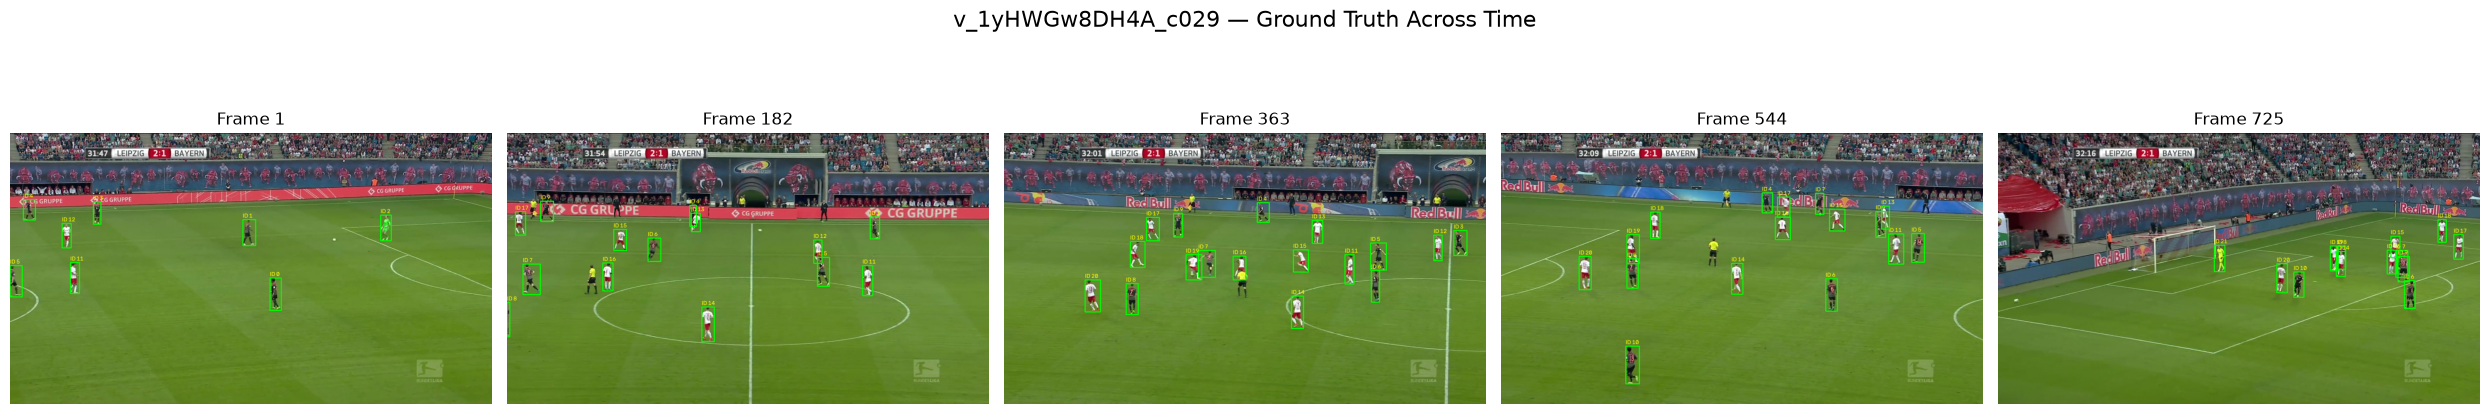

Frames visualized: [1, 182, 363, 544, 725]


In [17]:
# Visualize Ground Truth tracks across multiple frames

sequence = train_sequences[0]

img_dir = sequence / "img1"
gt_file = sequence / "gt" / "gt.txt"

# Load GT annotations
gt = pd.read_csv(
    gt_file,
    header=None,
    names=[
        "frame",
        "track_id",
        "x",
        "y",
        "width",
        "height",
        "mark",
        "class",
        "visibility"
    ]
)

# Select five frames spread across the sequence
total_frames = len(list(img_dir.glob("*.jpg")))

frame_numbers = np.linspace(
    1,
    total_frames,
    5,
    dtype=int
)

fig, axes = plt.subplots(
    1,
    5,
    figsize=(25, 5)
)

for ax, frame_number in zip(axes, frame_numbers):

    image_path = img_dir / f"{frame_number:06d}.jpg"

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    frame_gt = gt[gt["frame"] == frame_number]

    for _, row in frame_gt.iterrows():

        x = int(row["x"])
        y = int(row["y"])
        w = int(row["width"])
        h = int(row["height"])
        track_id = int(row["track_id"])

        cv2.rectangle(
            image,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

        cv2.putText(
            image,
            f"ID {track_id}",
            (x, max(y - 5, 15)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (255, 255, 0),
            1,
            cv2.LINE_AA
        )

    ax.imshow(image)
    ax.set_title(f"Frame {frame_number}")
    ax.axis("off")

plt.suptitle(
    f"{sequence.name} — Ground Truth Across Time",
    fontsize=16
)

plt.tight_layout()
plt.show()

print("Frames visualized:", frame_numbers.tolist())